In [1]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import new_calcium_model, simulate_dipole, jones_2009_model

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology

# import pandas as pd
from scipy import signal
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'


# colormap settings
from matplotlib import colormaps
import matplotlib.patches as mpatches

cmap = colormaps['Set2']

cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[3], 'L5_pyramidal': cmap.colors[4]}


# Hack a colormap

from scipy.interpolate import RectBivariateSpline
from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d
from hnn_core.viz import plot_laminar_csd

In [2]:
def find_rheo(model='jones'):

    fig, ax = plt.subplots(2,2, figsize=(12, 10))
    ax = ax.ravel()

    ampl = np.linspace(0.01, 1., 80)
    rheo = np.zeros((4,))

    for a in ampl: 
        if model == 'jones':
            net = jones_2009_model(mesh_shape=(1,1))
        else:
            net = new_calcium_model(mesh_shape=(1,1))

        net.clear_connectivity()

        net.add_tonic_bias(cell_type='L2_basket', amplitude=a, t0=10., tstop=100.)
        net.add_tonic_bias(cell_type='L5_basket', amplitude=a, t0=10., tstop=100.)

        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100.)
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100.)

        dpl = simulate_dipole(net, tstop=100, n_trials=1, dt =0.01, record_vsec='soma')

        for i in range(4):

            if i == 2:
                rheo[i] == rheo[0]
            if rheo[i] == 0:
                if any((np.array(net.cell_response.spike_gids[0]) == i)):
                    rheo[i] = a
                    ax[i].plot(net.cell_response.times, net.cell_response.vsec[0][i]['soma'])
                    break

    return rheo

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60

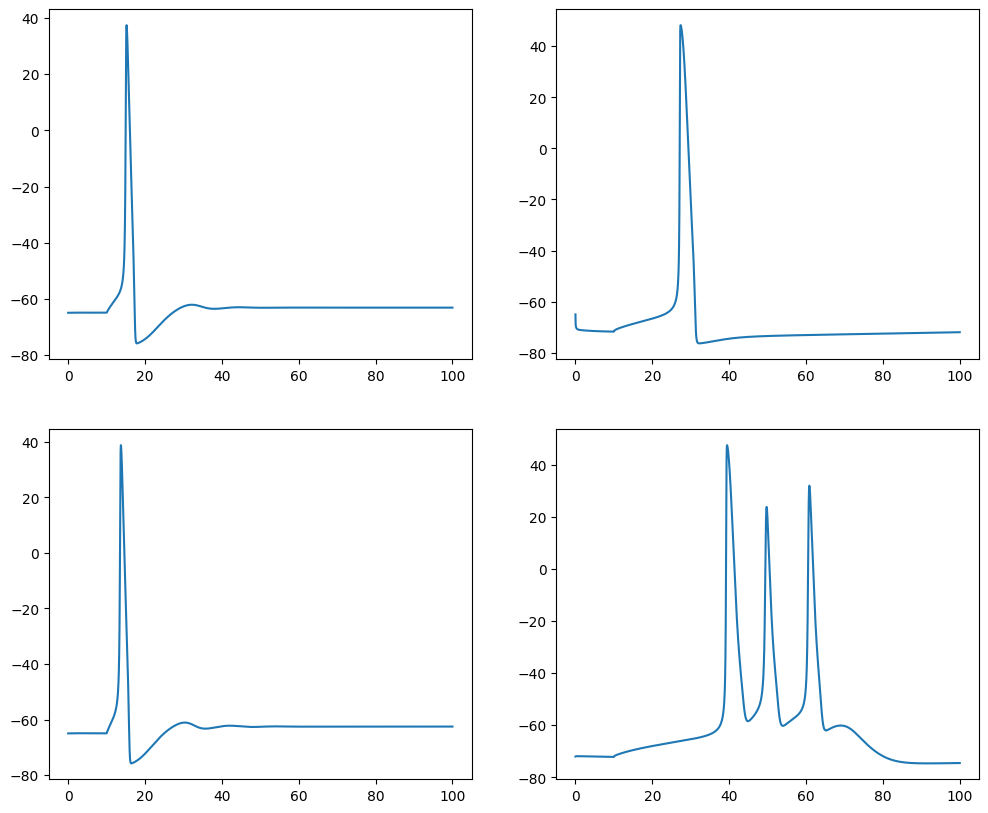

In [3]:
# find rheobases for Jones cells

rheo_jones = find_rheo(model='jones')


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
B

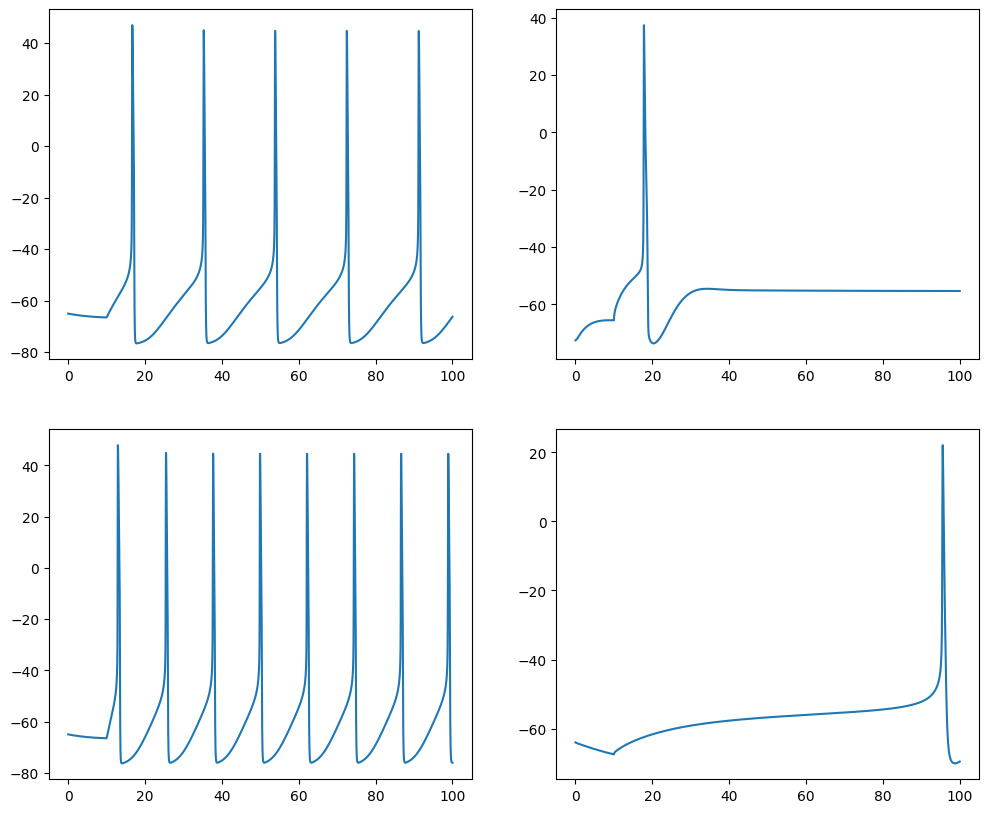

In [4]:
# find rheobases for new cells
rheo_ca = find_rheo(model='ca')

In [5]:
# rheobase plots
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']

jonnet = jones_2009_model(mesh_shape=(1,1))
jonnet.clear_connectivity()

canet = new_calcium_model(mesh_shape=(1,1))
canet.clear_connectivity()

for i,c in enumerate(cell_types):
    jonnet.add_tonic_bias(cell_type=c, amplitude=rheo_jones[i], t0=10., tstop=1000.)
    canet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=1000.)

dpl_jon = simulate_dipole(jonnet, tstop=1200, n_trials=1, record_vsec='soma')
dpl_ca = simulate_dipole(canet, tstop=1200, n_trials=1, record_vsec='soma')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Trial 1: 360.0 ms...
Trial 1: 370.0 ms...
Trial 1: 380.0 ms...
Trial 1: 390.0 ms...
Trial 1: 400.0 ms...
Trial 1: 410.0 ms...
Trial 1: 420.0 ms...

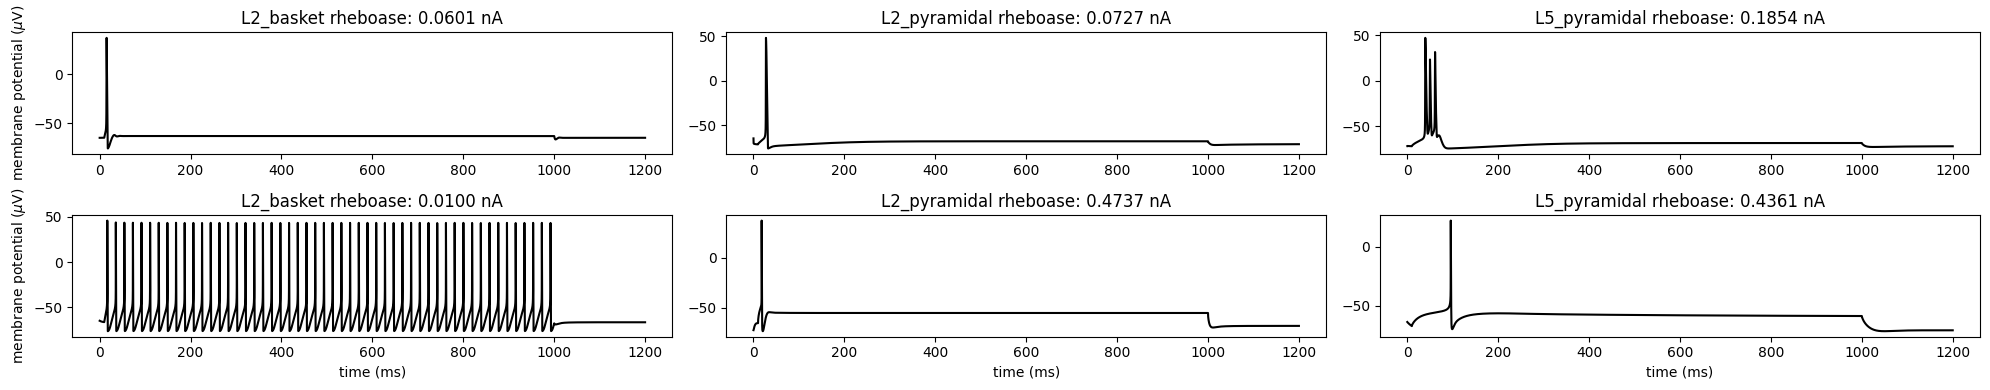

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(20, 4))

for i in range(3):
    if i == 2:
        c = i+1
    else:
        c = i
    ax[0,i].plot(jonnet.cell_response.times, jonnet.cell_response.vsec[0][c]['soma'], color='k')
    ax[1,i].plot(jonnet.cell_response.times, canet.cell_response.vsec[0][c]['soma'], color='k')
    ax[0,i].set_title(f'{cell_types[c]} rheboase: {rheo_jones[c]:.4f} nA')
    ax[1,i].set_title(f'{cell_types[c]} rheboase: {rheo_ca[c]:.4f} nA')
    ax[1,i].set_xlabel('time (ms)')
    ax[0,0].set_ylabel('membrane potential ($\mu$V)')
    ax[1,0].set_ylabel('membrane potential ($\mu$V)')

fig.tight_layout()
fig.savefig(pathfig + 'rheobase_comparison.png')

## Jones model behavior

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


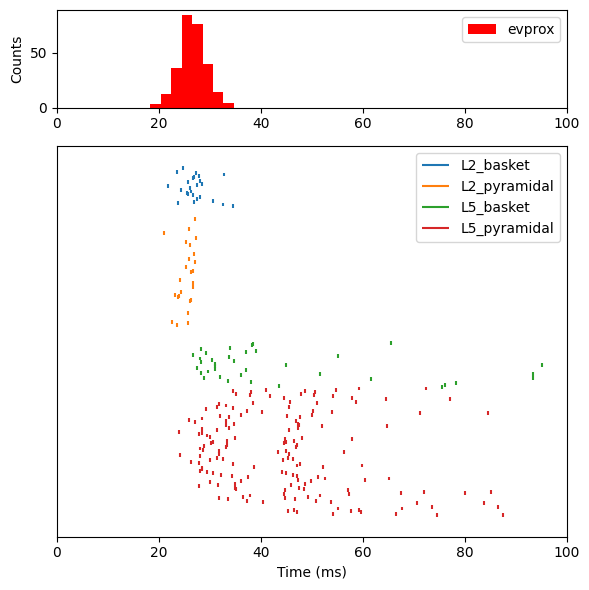

In [14]:
net = jones_2009_model()

weights_ampa_p1 = {'L2_basket': 1, 'L2_pyramidal': .5,
                   'L5_basket': 1, 'L5_pyramidal': .5}
weights_nmda_p1 = {'L2_basket': 1, 'L2_pyramidal':.5,
                   'L5_basket': 1, 'L5_pyramidal': .5}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}


# all NMDA weights are zero; pass None explicitly
net.add_evoked_drive(
    'evprox', mu=26.61, sigma=2.47, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


fig, ax = plt.subplots(2,1, figsize=(6, 6), height_ratios=[0.25, 1])

net.cell_response.plot_spikes_hist(ax=ax[0], spike_types=['evprox'], show=False)
net.cell_response.plot_spikes_raster(ax=ax[1], show=False)

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_spikes_prox.png'))

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
B

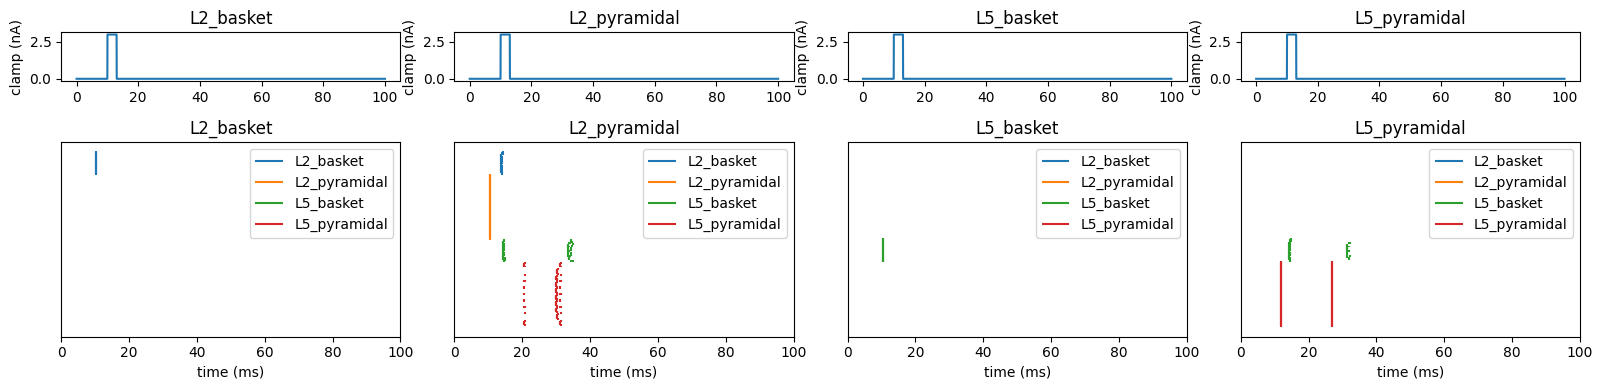

In [15]:

fig, ax = plt.subplots(2,4, figsize=(16, 4), height_ratios=[0.25, 1])

for i,c in enumerate(cell_types):
    # stimulate L2/3 pyramidal
    net = jones_2009_model()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2200,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    ampl = 3.
    t0 = 10

    net.add_tonic_bias(cell_type=c,section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

    dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

    # clamp signal for plotting
    timevec = net.cell_response.times

    clamp = np.zeros_like(timevec) 

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
            tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

            clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']
    
    


    ax[0,i].plot(timevec, clamp)
    ax[0,i].set_ylabel('clamp (nA)')
    ax[0,i].set_title(f'{cell_types[i]}')
    net.cell_response.plot_spikes_raster(ax=ax[1,i], show=False)
    ax[1,i].set_title(f'{cell_types[i]}')
    ax[1,i].set_xlabel('time (ms)')

    del net

for i in range(3):
    ax[1,i].set_ylim([ax[1,3].get_ylim()[0],ax[1,3].get_ylim()[1]])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_inter_layer.png'))

In [19]:
net = jones_2009_model()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 10

net.add_tonic_bias(cell_type='L2_pyramidal',section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

np_gid = np.array(net.cell_response.spike_gids[0])
bask_spike_gid = np_gid[np.where((np_gid >= 135) & (np_gid < 170))[0]]
pyr_spike_gid = np_gid[np.where((np_gid >= 170) & (np_gid < 270))[0]]
l23_spike_gid = np_gid[np.where((np_gid >= 35) & (np_gid < 135))[0]]

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


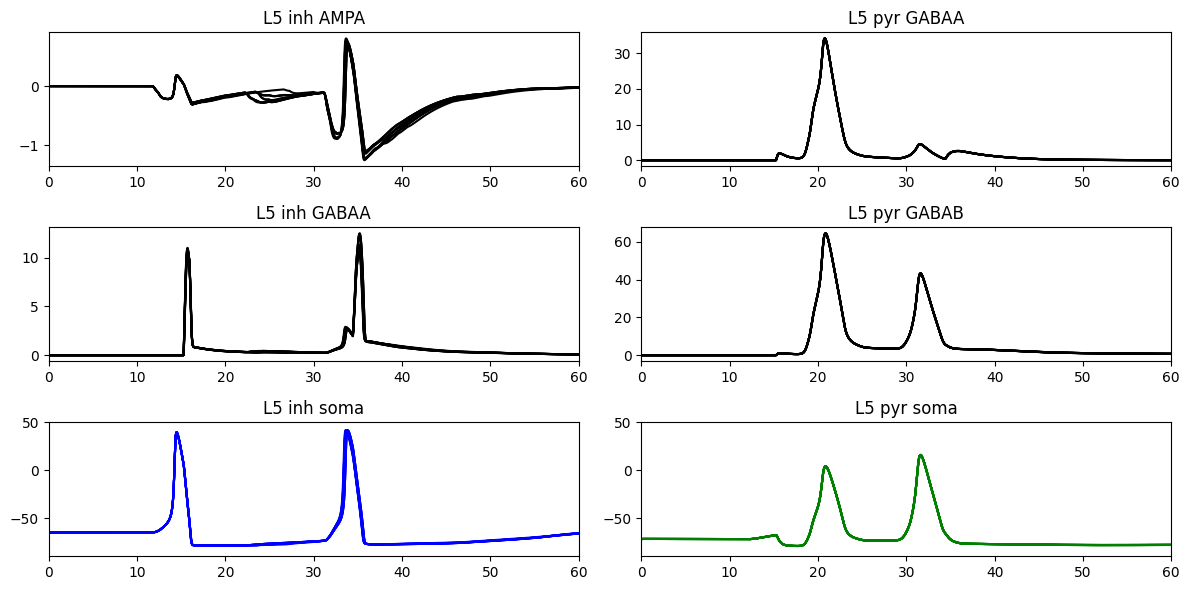

In [18]:
# Spiking in L5 caused by hyperpolarization? 
# this is actually unlikely because driving L5 basket does not drive L5 pyramidal
l5b_ampa = np.zeros((10,len(net.cell_response.times)))
l5b_nmda = np.zeros((10,len(net.cell_response.times)))
l5b_gabaa = np.zeros((10,len(net.cell_response.times)))
somav_i = np.zeros((10, len(net.cell_response.times)))
somav_e = np.zeros((10, len(net.cell_response.times)))

for i,igid in enumerate(bask_spike_gid[:10]):
    l5b_ampa[i] = net.cell_response.isec[0][igid]['soma']['soma_ampa']
    l5b_nmda[i] = net.cell_response.isec[0][igid]['soma']['soma_nmda']
    l5b_gabaa[i] = net.cell_response.isec[0][igid]['soma']['soma_gabaa']
    somav_i[i] = net.cell_response.vsec[0][igid]['soma']


l5p_gabaa = np.zeros((10,len(net.cell_response.times)))
l5p_gabab = np.zeros((10,len(net.cell_response.times)))

for i,igid in enumerate(pyr_spike_gid[:10]):
    l5p_gabaa[i] = net.cell_response.isec[0][igid]['soma']['soma_gabaa']
    l5p_gabab[i] = net.cell_response.isec[0][igid]['soma']['soma_gabab']
    somav_e[i] = net.cell_response.vsec[0][igid]['soma']

timevec = np.tile(net.cell_response.times.reshape(1,-1),(10,1)).T
fig, ax = plt.subplots(3,2, figsize=(12, 6))
ax[0,0].plot(timevec, l5b_ampa.T, color='k')#, alpha = 0.2)
ax[0,0].set_title('L5 inh AMPA')
ax[1,0].plot(timevec, l5b_gabaa.T, color='k')#, alpha = 0.2)
ax[1,0].set_title('L5 inh GABAA')


ax[0,1].plot(timevec, l5p_gabaa.T, color='k')#, alpha = 0.2)
ax[0,1].set_title('L5 pyr GABAA')
ax[1,1].plot(timevec, l5p_gabab.T, color='k')#, alpha = 0.2)
ax[1,1].set_title('L5 pyr GABAB')

ax[2,0].plot(timevec, somav_i.T, color='b')#, alpha=0.1)
ax[2,0].set_title('L5 inh soma')
ax[2,1].plot(timevec, somav_e.T, color='g')#, alpha=0.1)
ax[2,1].set_title('L5 pyr soma')
ax[2,1].set_ylim([-90, 50])
ax[2,0].set_ylim([-90, 50])


ax = ax.ravel()
for a in ax:
    a.set_xlim([0, 60])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_investigate_l5spike.png'))

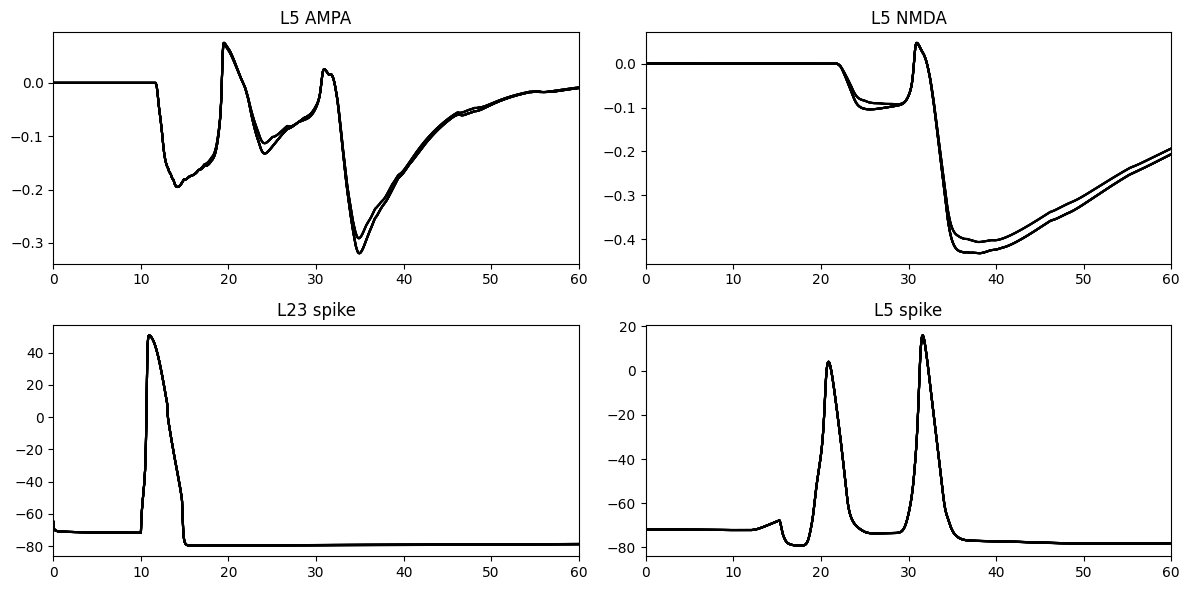

In [25]:
# Spiking in L5 caused by hyperpolarization? 
# this is actually unlikely because driving L5 basket does not drive L5 pyramidal
l23_spike = np.zeros((10,len(net.cell_response.times)))
l5_nmda = np.zeros((10,len(net.cell_response.times)))
l5_ampa = np.zeros((10,len(net.cell_response.times)))

for i,igid in enumerate(l23_spike_gid[:10]):
    l23_spike[i] = net.cell_response.vsec[0][igid]['soma']

for i,igid in enumerate(pyr_spike_gid[:10]):
    l5_nmda[i] = net.cell_response.isec[0][igid]['apical_oblique']['apical_oblique_nmda']
    l5_ampa[i] = net.cell_response.isec[0][igid]['apical_oblique']['apical_oblique_ampa']
    somav_e[i] = net.cell_response.vsec[0][igid]['soma']

timevec = np.tile(net.cell_response.times.reshape(1,-1),(10,1)).T
fig, ax = plt.subplots(2,2, figsize=(12, 6))
ax[0,0].plot(timevec, l5_ampa.T, color='k')#, alpha = 0.2)
ax[0,0].set_title('L5 AMPA')
ax[0,1].plot(timevec, l5_nmda.T, color='k')#, alpha = 0.2)
ax[0,1].set_title('L5 NMDA')

ax[1,0].plot(timevec, l23_spike.T, color='k')#, alpha = 0.2)
ax[1,0].set_title('L23 spike')

ax[1,1].plot(timevec, somav_e.T, color='k')#, alpha = 0.2)
ax[1,1].set_title('L5 spike')


ax = ax.ravel()
for a in ax:
    a.set_xlim([0, 60])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_investigate_l5spike.png'))

## New calcium model same drive

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/cell.py:93: RuntimeWarning: divide by zero encountered in scalar divide
  delay = nc_dict['A_delay'] / _calculate_gaussian(


[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


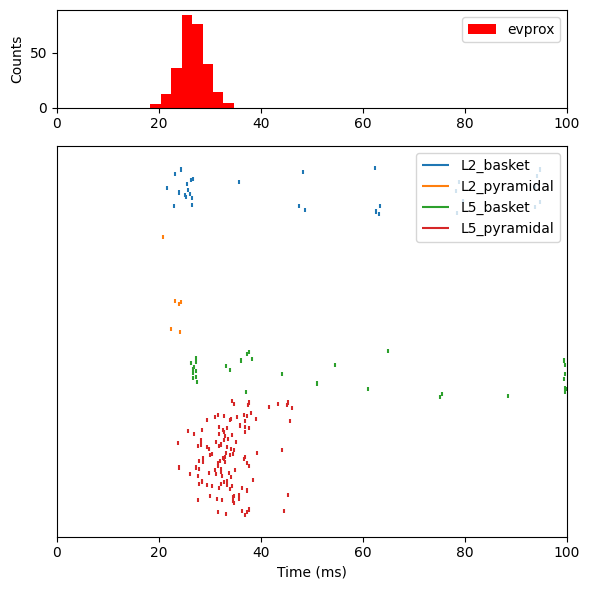

In [2]:
net = new_calcium_model()

weights_ampa_p1 = {'L2_basket': 1, 'L2_pyramidal': .5,
                   'L5_basket': 1, 'L5_pyramidal': .5}
weights_nmda_p1 = {'L2_basket': 1, 'L2_pyramidal':.5,
                   'L5_basket': 1, 'L5_pyramidal': .5}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}


# all NMDA weights are zero; pass None explicitly
net.add_evoked_drive(
    'evprox', mu=26.61, sigma=2.47, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


fig, ax = plt.subplots(2,1, figsize=(6, 6), height_ratios=[0.25, 1])

net.cell_response.plot_spikes_hist(ax=ax[0], spike_types=['evprox'], show=False)
net.cell_response.plot_spikes_raster(ax=ax[1], show=False)
# ax2 = ax[1].twinx()
# ax2.plot(dpl[0].times, dpl[0].data['agg'], color='k')
fig.tight_layout()

fig.savefig(os.path.join(pathfig, 'c_new_model_spikes_prox.png'))

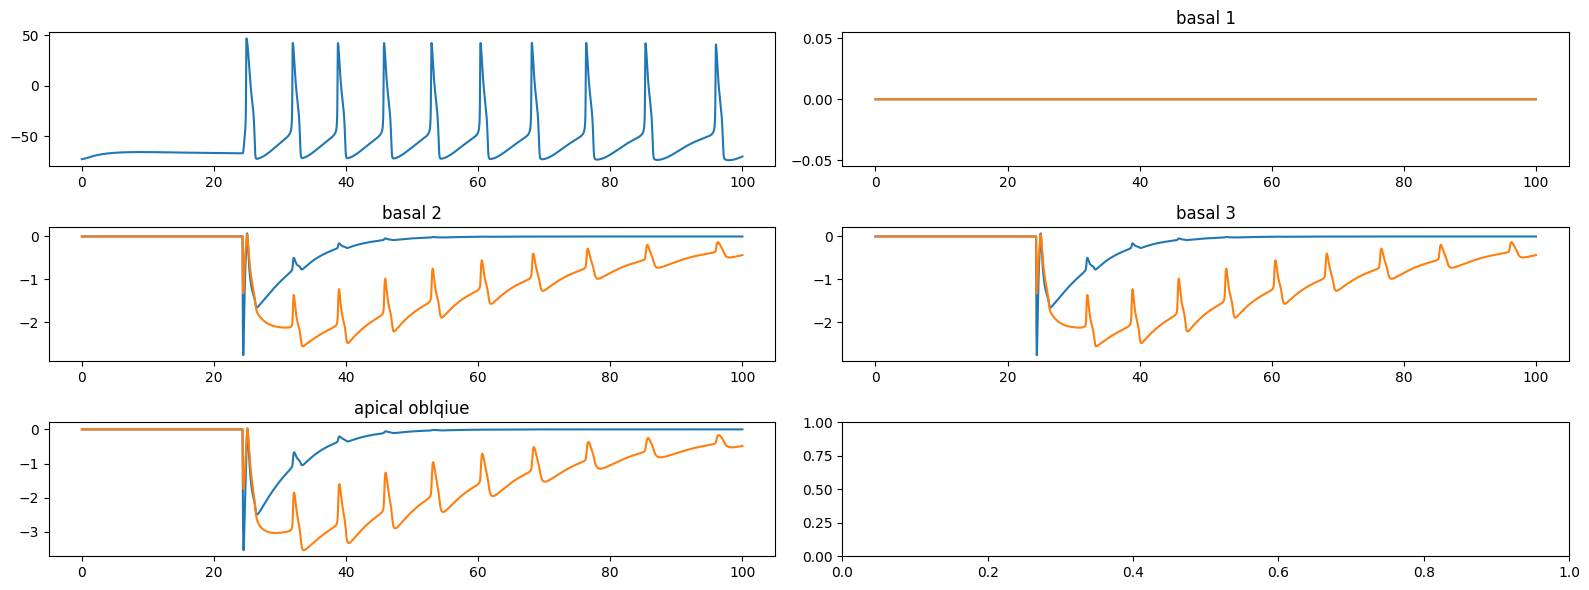

In [3]:
values_l23, counts_l23 = np.unique(np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) > 35) & (np.array(net.cell_response.spike_gids[0]) <135)], return_counts=True)

gid_oi = values_l23[np.argmax(counts_l23)]

fig, ax = plt.subplots(3,2, figsize=(16, 6))
ax = ax.ravel()
ax[0].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'])
ax[1].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_1']['basal_1_ampa'])
ax[1].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_1']['basal_1_nmda'])
ax[1].set_title('basal 1')
ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_ampa'])
ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_nmda'])
ax[2].set_title('basal 2')
ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_ampa'])
ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_nmda'])
ax[3].set_title('basal 3')
ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_ampa'])
ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_nmda'])
ax[4].set_title('apical oblqiue')

fig.tight_layout()

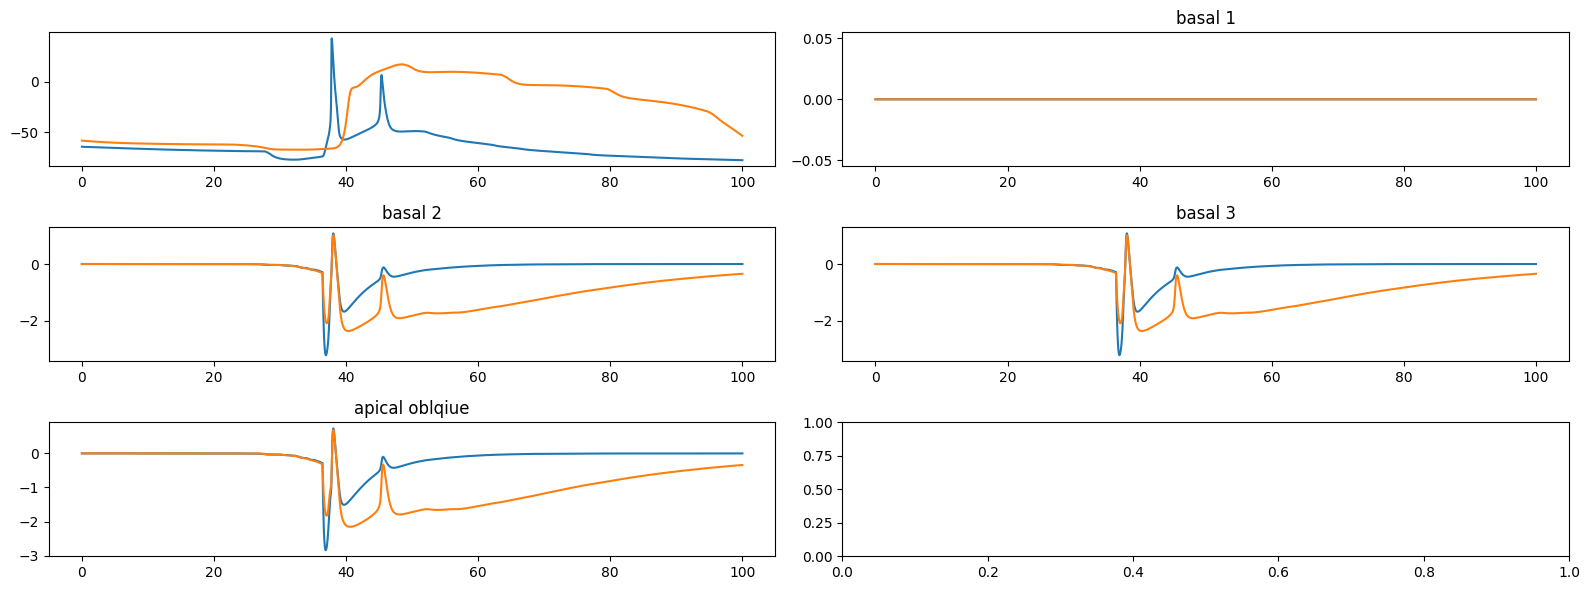

In [3]:
values_l5, counts_l5 = np.unique(np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) > 170) & (np.array(net.cell_response.spike_gids[0]) <270)], return_counts=True)
gid_oi = values_l5[np.argmax(counts_l5)]

fig, ax = plt.subplots(3,2, figsize=(16, 6))
ax = ax.ravel()
ax[0].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'])
ax[0].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['apical_tuft'])

ax[1].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_1']['basal_1_ampa'])
ax[1].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_1']['basal_1_nmda'])
ax[1].set_title('basal 1')
ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_ampa'])
ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_nmda'])
ax[2].set_title('basal 2')
ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_ampa'])
ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_nmda'])
ax[3].set_title('basal 3')
ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_ampa'])
ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_nmda'])
ax[4].set_title('apical oblqiue')

fig.tight_layout()

In [4]:
counts_l5

array([1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 1, 1,
       1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       1, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1, 2, 2, 1, 1, 1,
       2, 2, 1, 1])

In [6]:
many_spikes = values_l5[counts_l5 >= 2]
few_spikes = values_l5[counts_l5 < 2]
many_spikes

array([173., 174., 175., 182., 183., 184., 185., 186., 187., 191., 192.,
       193., 195., 196., 201., 202., 204., 205., 206., 207., 208., 210.,
       211., 212., 213., 214., 215., 216., 217., 218., 220., 221., 222.,
       223., 225., 226., 227., 231., 232., 233., 234., 235., 236., 241.,
       242., 244., 245., 253., 254.])

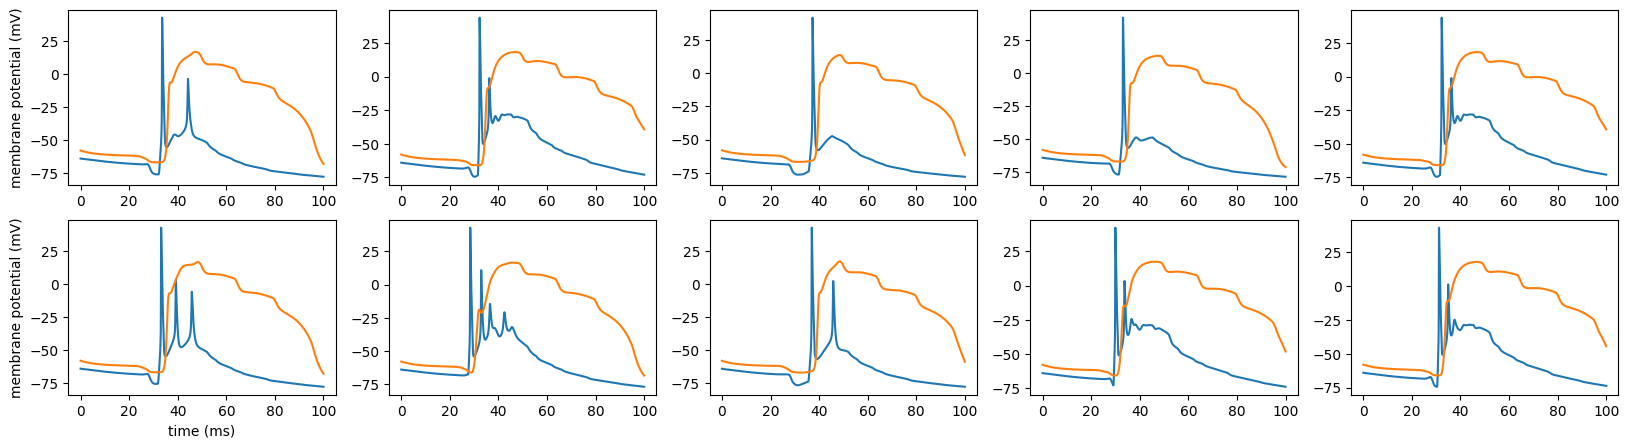

In [7]:
fig, ax = plt.subplots(2,5, figsize=(20, 5))

sel_random = np.random.choice(len(few_spikes), 5)
for i,gid_oi in enumerate(few_spikes[sel_random]):
    ax[0,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'])
    ax[0,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['apical_tuft'])

sel_random = np.random.choice(len(many_spikes), 5)
for i,gid_oi in enumerate(many_spikes[sel_random]):
    ax[1,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'])
    ax[1,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['apical_tuft'])

ax[0,0].set_ylabel('membrane potential (mV)')
ax[1,0].set_ylabel('membrane potential (mV)')
ax[1,0].set_xlabel('time (ms)')

fig.savefig(os.path.join(pathfig, 'few_vs_many_aps_calcium_spike.png'))

In [8]:
from hnn_core.cell import _get_gaussian_connection

# this is from the plotting function
exc_cells = ['L2_pyramidal', 'L5_pyramidal']
inh_cells = ['L2_basket', 'L5_basket']

conn_strength_exc = dict()
conn_strength_inh = dict()


for conn in net.connectivity:
    nc_dict = conn['nc_dict']
    src_type = conn['src_type']
    target_type = conn['target_type']
    src_type_pos = net.pos_dict[src_type]
    target_type_pos = net.pos_dict[target_type]

    src_range = np.array(net.gid_ranges[conn['src_type']])
    target_range = np.array(net.gid_ranges[conn['target_type']])
    connectivity_matrix = np.zeros((len(src_range), len(target_range)))

    for src_gid, target_src_pair in conn['gid_pairs'].items():
        src_idx = np.where(src_range == src_gid)[0][0]
        target_indeces = np.where(np.isin(target_range, target_src_pair))[0]
        for target_idx in target_indeces:
            src_pos = src_type_pos[src_idx]
            target_pos = target_type_pos[target_idx]

            weight, _ = _get_gaussian_connection(
                src_pos, target_pos, nc_dict,
                inplane_distance=net._inplane_distance)

            connectivity_matrix[src_idx, target_idx] = weight

    if conn['src_type'] in exc_cells:
        conn_strength_exc[conn['src_type'] + '-' + conn['target_type']] = connectivity_matrix.sum()
    elif conn['src_type'] in inh_cells:
        conn_strength_inh[conn['src_type'] + '-' + conn['target_type']] = connectivity_matrix.sum()




In [9]:
np.array(list(conn_strength_exc.values())).sum(),np.array(list(conn_strength_inh.values())).sum()

(np.float64(2.880572909501076), np.float64(307.36112490318413))

In [10]:
np.array(list(conn_strength_exc.values())).mean(),np.array(list(conn_strength_inh.values())).mean()

(np.float64(0.480095484916846), np.float64(61.472224980636824))

Text(0, 0.5, 'count')

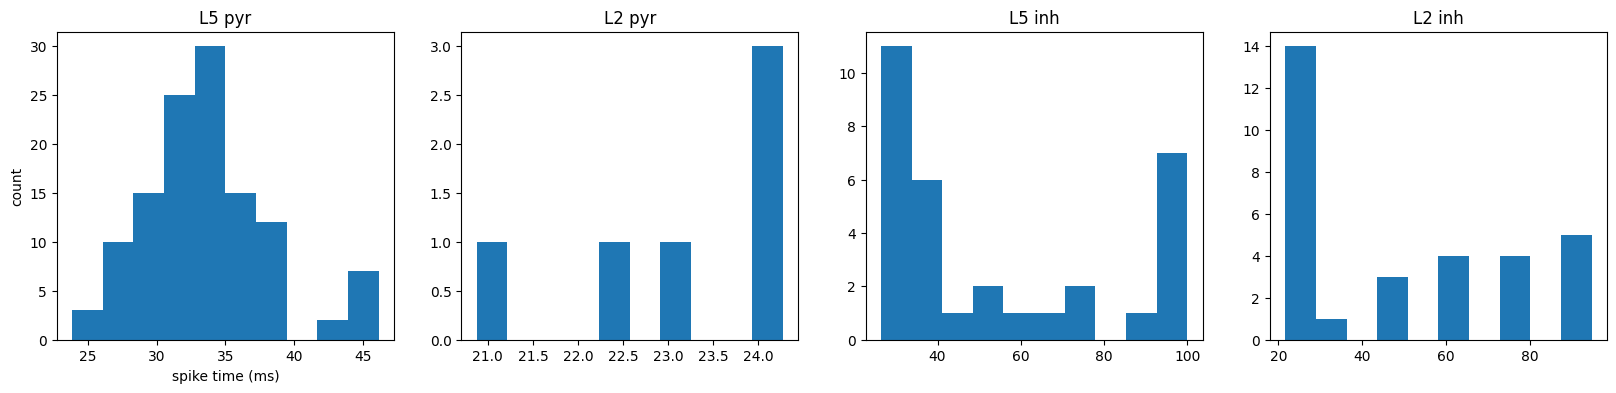

In [11]:
fig, ax = plt.subplots(1,4, figsize=(20, 4))
ax[0].hist(net.cell_response.spike_times_by_type['L5_pyramidal'])
ax[1].hist(net.cell_response.spike_times_by_type['L2_pyramidal'])
ax[2].hist(net.cell_response.spike_times_by_type['L5_basket'])
ax[3].hist(net.cell_response.spike_times_by_type['L2_basket'])

ax[0].set_title('L5 pyr')
ax[1].set_title('L2 pyr')
ax[2].set_title('L5 inh')
ax[3].set_title('L2 inh')

ax[0].set_xlabel('spike time (ms)')
ax[0].set_ylabel('count')

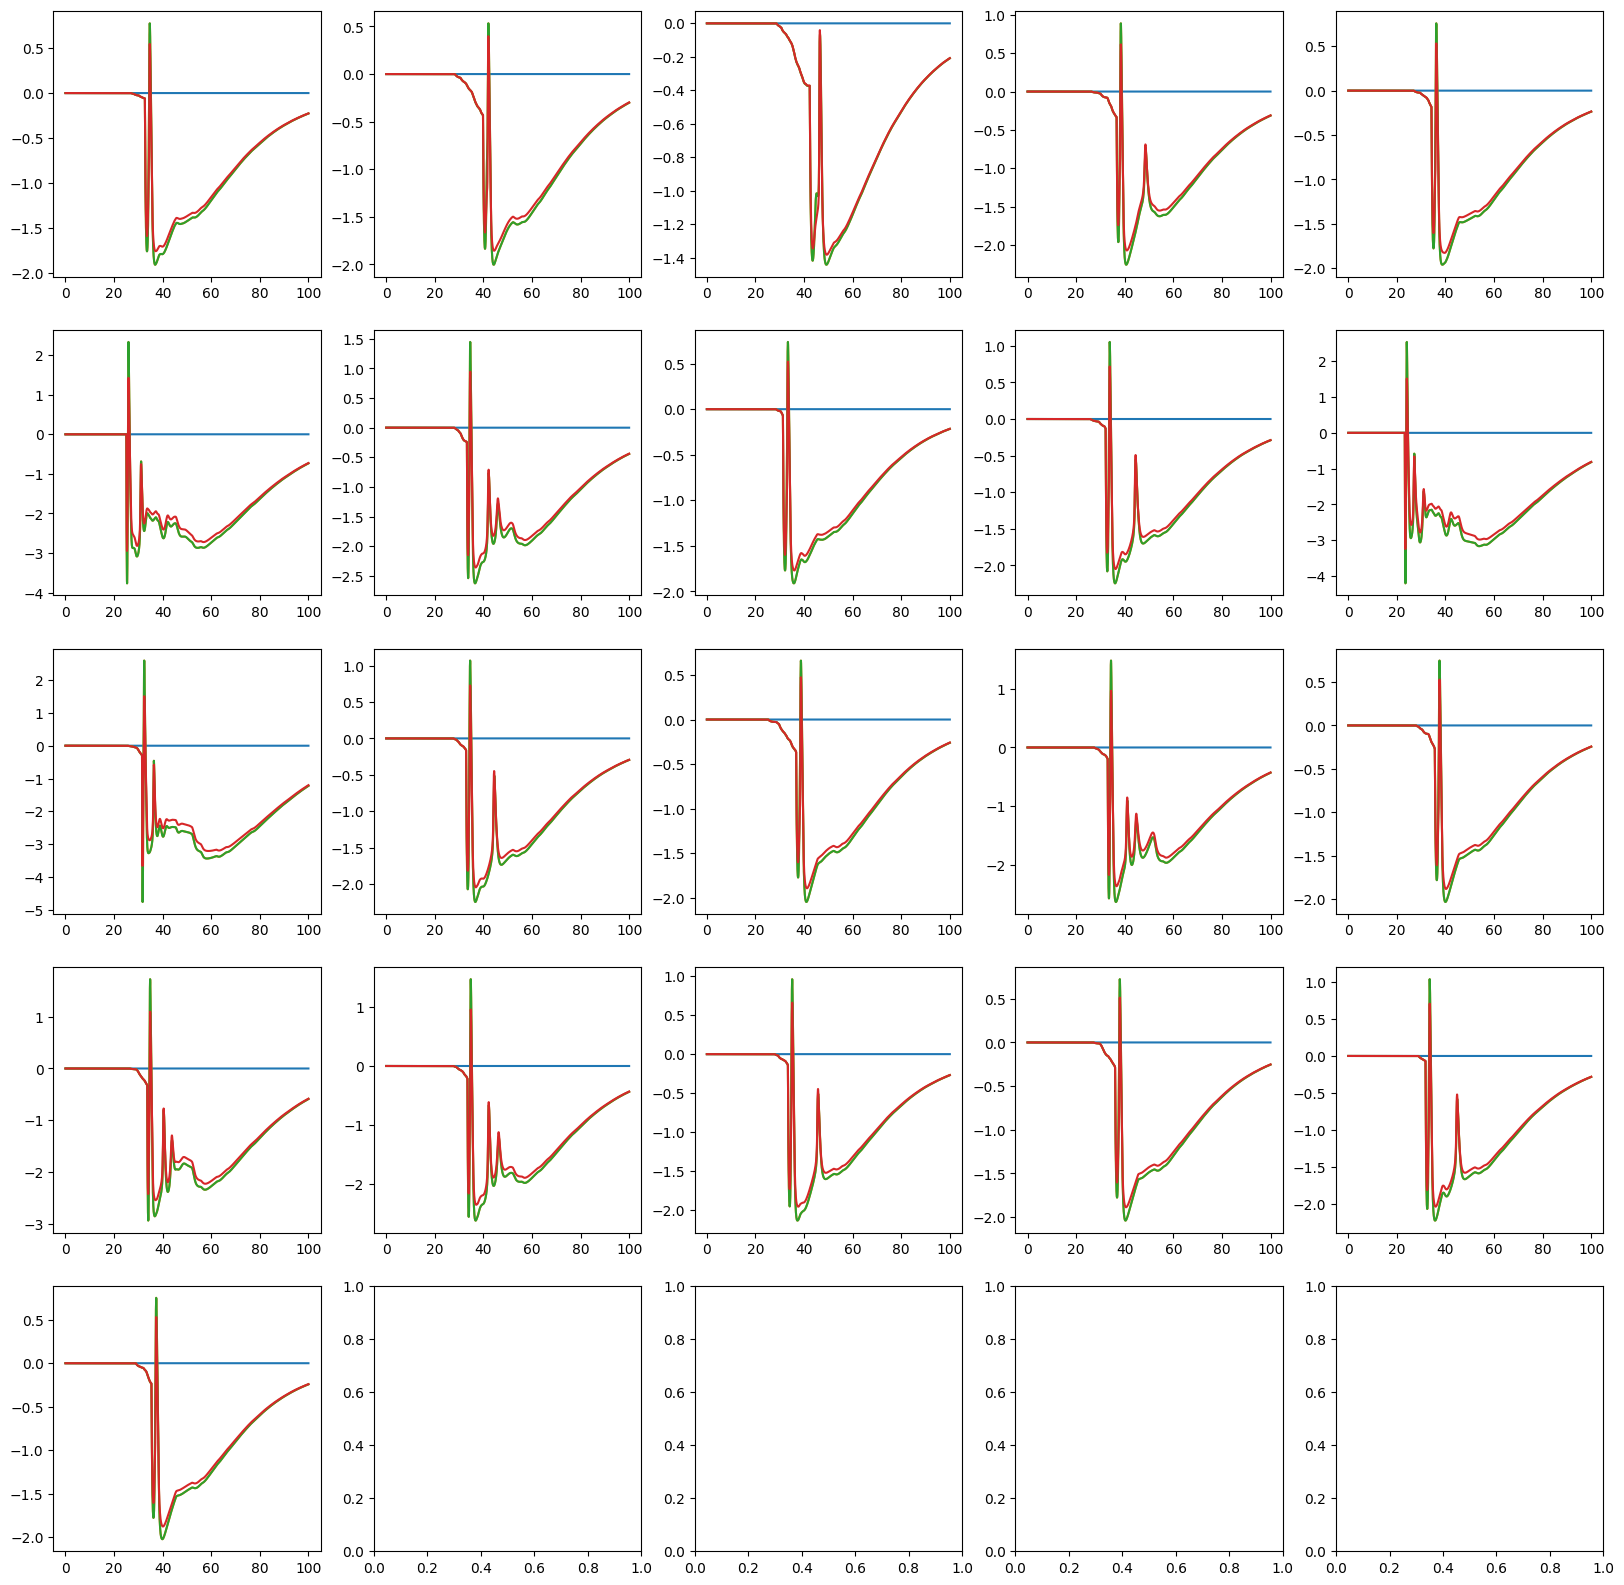

In [12]:
fig, ax = plt.subplots(5,5, figsize=(20, 20))
ax = ax.ravel()

for i,gid_oi in enumerate(few_spikes[:25]):
    ax[i].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_1']['basal_1_nmda'])
    ax[i].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_nmda'])
    ax[i].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_nmda'])
    ax[i].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_nmda'])

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
B

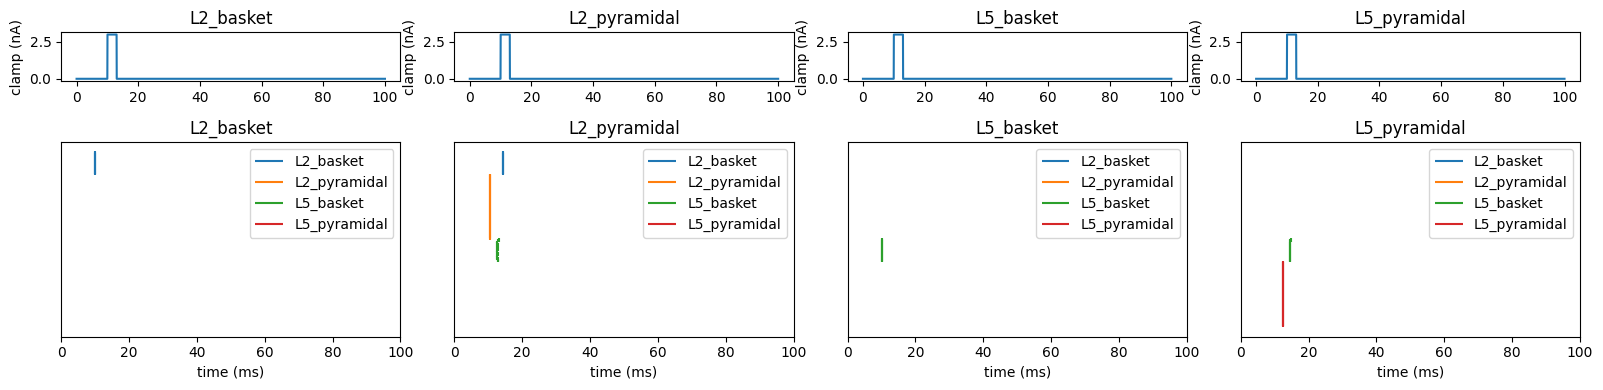

In [13]:
fig, ax = plt.subplots(2,4, figsize=(16, 4), height_ratios=[0.25, 1])

cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
for i,c in enumerate(cell_types):
    # stimulate L2/3 pyramidal
    net = new_calcium_model()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2200,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    ampl = 3.
    t0 = 10

    net.add_tonic_bias(cell_type=c,section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

    dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

    # clamp signal for plotting
    timevec = net.cell_response.times

    clamp = np.zeros_like(timevec) 

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
            tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

            clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']
    
    


    ax[0,i].plot(timevec, clamp)
    ax[0,i].set_ylabel('clamp (nA)')
    ax[0,i].set_title(f'{cell_types[i]}')
    net.cell_response.plot_spikes_raster(ax=ax[1,i], show=False)
    ax[1,i].set_title(f'{cell_types[i]}')
    ax[1,i].set_xlabel('time (ms)')

    del net

for i in range(3):
    ax[1,i].set_ylim([ax[1,3].get_ylim()[0],ax[1,3].get_ylim()[1]])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'new_model_inter_layer.png'))

In [ ]:
# from hnn_core.viz import plot_connectivity_matrix, plot_cell_connectivity
# from hnn_core.network import pick_connection

# print(len(net.connectivity))

# source_cells = ['L2_pyramidal', 'L2_pyramidal', 'L5_basket']
# target_cells = ['L5_basket', 'L5_pyramidal', 'L5_pyramidal']
# location = ['soma', 'distal', 'soma']
# receptors = ['ampa', 'ampa', 'gabaa']

# fig, ax = plt.subplots(1,3,figsize=(16,8))

# i = 0
# for source, target in zip(source_cells, target_cells):
#     conn_indices = pick_connection(
#         net=net, src_gids=source, target_gids=target,
#         loc=location[i], receptor=receptors[i])
#     conn_idx = conn_indices[0]
#     plot_connectivity_matrix(net, conn_idx, ax=ax[i], show=False)
#     i += 1

# fig.savefig(os.path.join(pathfig,f'conn_new_model.png'))

# # Note here that `'src_gids'` is a `set` object
# # The `.pop()` method can be used to sample a random element
# src_gid = net.connectivity[conn_idx]['src_gids'].copy().pop()
# fig = plot_cell_connectivity(net, conn_idx, src_gid)

# fig.savefig(os.path.join(pathfig,f'conn_{source_cells}_to_{target_cells}.png'))